# HW2 Classify a Music Catalog
113062273 許晉豪

依序執行所有 cells。資料放在 notebook 同一層，接受 `processed_tracks.csv` 或下載時的 `processed_tracks (1).csv`。只用指定的 13 個欄位；不改 starter、資料或 pre-report。圖表與數值輸出到 `HW2_results_113062273`。

沿用 pre-report：20% stratified test、5-fold stratified CV、seed 113062273。多類別用 CV macro-F1 選參數，相同分數採候選順序第一個。這是調參用 CV，最佳分數可能略樂觀，最後才評估 test，沒有另外加 nested CV。

In [1]:
from pathlib import Path
import json, hashlib, inspect, platform
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve,
    precision_recall_curve, auc, average_precision_score, recall_score)
from threadpoolctl import threadpool_limits

SEED = 113062273
threadpool_limits(limits=1)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
DATA = next((p for p in [Path('processed_tracks.csv'), Path('processed_tracks (1).csv'),
    Path('Hw2/processed_tracks.csv'), Path('Hw2/processed_tracks (1).csv')] if p.exists()), None)
if DATA is None:
    raise FileNotFoundError('Put processed_tracks.csv beside this notebook.')
OUT = DATA.parent / 'HW2_results_113062273'
OUT.mkdir(exist_ok=True)
FEATURES = ['danceability','energy','speechiness','acousticness','instrumentalness',
    'liveness','valence','loudness','tempo','key','mode','time_signature','duration_ms']
RARE = ['death-metal','tango','opera','black-metal','salsa']
df = pd.read_csv(DATA)
assert df.shape == (5300, 20) and df.track_id.is_unique
assert df[FEATURES].notna().all().all()
encoder = LabelEncoder().fit(df.track_genre)
names = encoder.classes_
labels = np.arange(len(names))
rare_ids = encoder.transform(RARE)
X_all = df[FEATURES].to_numpy(float)
y_all = encoder.transform(df.track_genre)
train_ids, test_ids = train_test_split(np.arange(len(df)), test_size=.2,
    stratify=y_all, random_state=SEED)
X, y = X_all[train_ids], y_all[train_ids]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y))
assert len(X)==4240 and len(test_ids)==1060
assert not set(train_ids) & set(test_ids)
assert np.array_equal(np.sort(np.concatenate([va for tr,va in folds])), np.arange(len(X)))
fold_data = []
for tr, va in folds:
    scaler = StandardScaler().fit(X[tr])
    fold_data.append((tr, va, scaler, scaler.transform(X[tr]), scaler.transform(X[va])))
summary = {'seed':SEED, 'n_train':len(X), 'n_test':len(test_ids),
    'versions':{'python':platform.python_version(),'numpy':np.__version__,
                'pandas':pd.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__},
    'data_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest()}
def save_table(name, table, show=True):
    table.to_csv(OUT / (name+'.csv'), index=False)
    if show: display(table)
    return table
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT/(name+'.png'), dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()
def metrics(yt, yp):
    p,r,f,_ = precision_recall_fscore_support(yt,yp,labels=labels,zero_division=0)
    result={'accuracy':accuracy_score(yt,yp), 'macro_f1':f.mean(),
            'micro_f1':f1_score(yt,yp,average='micro')}
    for genre,j in zip(RARE,rare_ids):
        result[genre+'_precision']=p[j]
        result[genre+'_recall']=r[j]
    result['rare_precision']=p[rare_ids].mean()
    result['rare_recall']=r[rare_ids].mean()
    return result
def pack(rows):
    table=pd.DataFrame(rows)
    return {key+'_'+suffix:float(table[key].mean() if suffix=='mean' else table[key].std(ddof=1))
            for key in table for suffix in ['mean','std']}
def evaluate(model, scale=False):
    rows=[]; oof=np.empty(len(y),dtype=int); train_rows=[]; leaves=[]
    for tr,va,sc,xt,xv in fold_data:
        if not scale: xt,xv=X[tr],X[va]
        m=clone(model).fit(xt,y[tr])
        oof[va]=m.predict(xv)
        rows.append(metrics(y[va],oof[va]))
        train_rows.append(metrics(y[tr],m.predict(xt)))
        if hasattr(m,'get_n_leaves'): leaves.append(m.get_n_leaves())
    r=pack(rows)
    r.update({'train_'+k:v for k,v in pack(train_rows).items()})
    if leaves: r['leaves_mean']=float(np.mean(leaves))
    return r,oof
def curves(table, key, filename, log=False):
    fig,axs=plt.subplots(1,2,figsize=(9,3))
    for ax,metric in zip(axs,['accuracy','macro_f1']):
        ax.plot(table[key],table['train_'+metric+'_mean'],label='Training')
        ax.errorbar(table[key],table[metric+'_mean'],yerr=table[metric+'_std'],
                    label='5-fold CV',capsize=2)
        if log: ax.set_xscale('log')
        ax.set(xlabel=key,ylabel=metric,ylim=(0,1.03)); ax.legend()
    savefig(filename)
save_table('split_counts',pd.DataFrame({'genre':names,
    'train':np.bincount(y,minlength=20), 'test':np.bincount(y_all[test_ids],minlength=20)}))
pd.DataFrame({'row':np.r_[train_ids,test_ids],
    'part':['train']*len(train_ids)+['test']*len(test_ids)}).to_csv(OUT/'split_rows.csv',index=False)
display(summary)

,genre,train,test
0,ambient,385,96
1,black-metal,46,12
2,bluegrass,164,41
3,blues,359,90
4,classical,185,46
5,comedy,382,95
6,country,113,28
7,death-metal,80,20
8,grunge,94,24
9,heavy-metal,178,45


{'seed': 113062273,
 'n_train': 4240,
 'n_test': 1060,
 'versions': {'python': '3.13.5',
  'numpy': '2.2.6',
  'pandas': '2.3.3',
  'scipy': '1.16.1',
  'sklearn': '1.7.1'},
 'data_sha256': '40167d80edc8edc694232b41f8c82052cb93348ea6bc40ec02a1277f9e86bf89'}

## 2 評估方法與 baseline
每折前處理只 fit 該折 training。以下重現 pre-report 的分層筆數和 baseline，並驗證 micro-F1 等於 accuracy。標準差使用五折樣本標準差 ddof=1。

In [2]:
count_rows=[]
for regime,splitter in [('KFold',KFold(5,shuffle=True,random_state=SEED)),('StratifiedKFold',cv)]:
    for j,(tr,va) in enumerate(splitter.split(X,y),1):
        for genre,c in zip(RARE,rare_ids):
            count_rows.append({'regime':regime,'fold':j,'genre':genre,'count':int((y[va]==c).sum())})
save_table('rare_fold_counts',pd.DataFrame(count_rows))
baseline_rows=[]
for strategy in ['most_frequent','stratified']:
    r,pred=evaluate(DummyClassifier(strategy=strategy,random_state=SEED))
    assert np.isclose(r['accuracy_mean'],r['micro_f1_mean'])
    baseline_rows.append({'baseline':strategy,**r})
baselines=save_table('baselines',pd.DataFrame(baseline_rows))
p=np.bincount(y)/len(y)
summary['baseline_theory']={'majority_acc':float(p.max()),
    'majority_macro_f1':float(2*p.max()/(1+p.max())/20),
    'random_expected_acc':float(p@p),'random_asymptotic_macro_f1':.05}
print(summary['baseline_theory'])

,regime,fold,genre,count
0,KFold,1,death-metal,16
1,KFold,1,tango,8
2,KFold,1,opera,8
3,KFold,1,black-metal,13
4,KFold,1,salsa,7
5,KFold,2,death-metal,19
6,KFold,2,tango,14
7,KFold,2,opera,10
8,KFold,2,black-metal,6
9,KFold,2,salsa,5


,baseline,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,death-metal_recall_mean,...,train_black-metal_recall_mean,train_black-metal_recall_std,train_salsa_precision_mean,train_salsa_precision_std,train_salsa_recall_mean,train_salsa_recall_std,train_rare_precision_mean,train_rare_precision_std,train_rare_recall_mean,train_rare_recall_std
0,most_frequent,0.133726,0.000646,0.011795,0.000050,0.133726,0.000646,0.000,0.000000,0.000,...,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000
1,stratified,0.075943,0.012580,0.051959,0.009259,0.075943,0.012580,0.025,0.034233,0.025,...,0.005556,0.012423,0.0,0.0,0.0,0.0,0.011778,0.009751,0.012817,0.010403


{'majority_acc': 0.13372641509433963, 'majority_macro_f1': 0.011795298522987312, 'random_expected_acc': 0.07214745016019936, 'random_asymptotic_macro_f1': 0.05}


## 3.1 k-NN
固定 uniform vote、Euclidean distance。一次找 100 個鄰居，再累積票數，等同分別 fit k=1 到 100；同票依排序後的類別代碼決定，與 sklearn 一致。training score 包含自己。

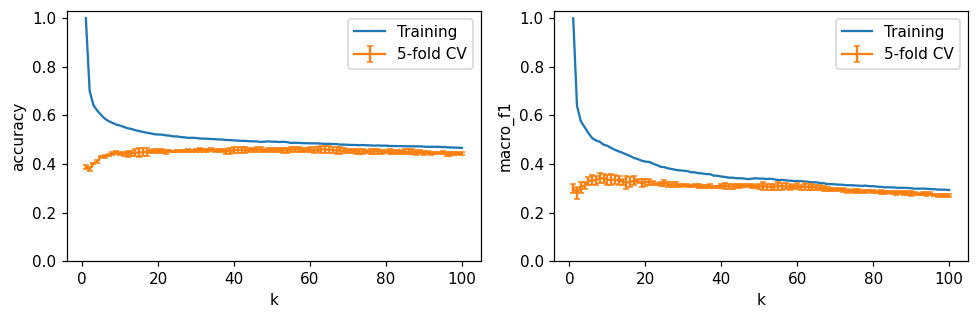

,k,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,train_micro_f1_mean,train_micro_f1_std,train_death-metal_precision_mean,train_death-metal_precision_std,train_death-metal_recall_mean,...,black-metal_recall_mean,black-metal_recall_std,salsa_precision_mean,salsa_precision_std,salsa_recall_mean,salsa_recall_std,rare_precision_mean,rare_precision_std,rare_recall_mean,rare_recall_std
0,1,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,0.108889,0.078724,0.530556,0.270102,0.485714,0.093984,0.237545,0.037108,0.220618,0.057220
2,3,0.642512,0.005014,0.576273,0.009007,0.642512,0.005014,0.530473,0.044628,0.568750,...,0.151111,0.124127,0.626667,0.277288,0.307143,0.140267,0.305198,0.069899,0.177107,0.057982
4,5,0.602476,0.004820,0.527351,0.013188,0.602476,0.004820,0.562507,0.040833,0.431250,...,0.171111,0.140897,0.461667,0.107303,0.307143,0.063638,0.303597,0.026197,0.202437,0.049699
7,8,0.569340,0.002565,0.491692,0.008133,0.569340,0.002565,0.513212,0.046033,0.387500,...,0.151111,0.124127,0.596667,0.275479,0.364286,0.131587,0.317758,0.074007,0.196491,0.035978
9,10,0.558373,0.002911,0.474956,0.007842,0.558373,0.002911,0.492637,0.042270,0.300000,...,0.128889,0.088052,0.507143,0.307475,0.314286,0.168748,0.318825,0.094586,0.168036,0.038955
19,20,0.521580,0.003478,0.409994,0.003509,0.521580,0.003478,0.515976,0.043401,0.184375,...,0.042222,0.057948,0.600000,0.547723,0.135714,0.175237,0.349697,0.175700,0.102730,0.037716
49,50,0.492040,0.000978,0.339956,0.004756,0.492040,0.000978,0.510909,0.129448,0.046875,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.231111,0.106400,0.058709,0.027488
56,57,0.486969,0.003497,0.332746,0.005917,0.486969,0.003497,0.435714,0.160074,0.037500,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.217143,0.113569,0.052912,0.031029
99,100,0.466333,0.006079,0.292842,0.004826,0.466333,0.006079,0.783333,0.217307,0.028125,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.136000,0.092087,0.014588,0.010951


,row,track,true,predicted,votes
0,1379,Credi In Te,opera,ambient,ambient:2; blues:1; classical:1; jazz:2; r-n-b...
1,3320,Mercedes,reggae,hip-hop,blues:2; comedy:2; hip-hop:3; reggae:1
2,470,The Sound Above My Hair - Radio Edit,techno,heavy-metal,bluegrass:1; blues:1; grunge:1; heavy-metal:2;...


,query_row,rank,neighbor_row,genre,distance
0,1379,1,3641,blues,2.355324
1,1379,2,4621,r-n-b,2.520167
2,1379,3,4556,classical,2.592353
3,1379,4,2156,tango,2.648187
4,1379,5,1395,jazz,2.689916
5,1379,6,2181,ambient,2.710745
6,1379,7,3412,jazz,2.744025
7,1379,8,3665,ambient,2.822680
8,3320,1,573,hip-hop,0.922479
9,3320,2,3858,comedy,0.938332


,N,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,death-metal_recall_mean,...,salsa_precision_mean,salsa_precision_std,salsa_recall_mean,salsa_recall_std,rare_precision_mean,rare_precision_std,rare_recall_mean,rare_recall_std,retention_mean,retention_std
0,0,0.442925,0.006491,0.341971,0.019107,0.442925,0.006491,0.265455,0.211097,0.1875,...,0.596667,0.275479,0.364286,0.131587,0.317758,0.074007,0.196491,0.035978,1.000000,0.000000
1,5,0.400472,0.006650,0.270845,0.010350,0.400472,0.006650,0.076515,0.074824,0.0375,...,0.200000,0.447214,0.028571,0.063888,0.186287,0.188299,0.058279,0.034403,0.265271,0.004816
2,20,0.356368,0.018428,0.227073,0.016976,0.356368,0.018428,0.158333,0.119315,0.0750,...,0.000000,0.000000,0.000000,0.000000,0.073000,0.027998,0.024231,0.010230,0.091716,0.004098
3,50,0.298821,0.011956,0.188494,0.012722,0.298821,0.011956,0.290000,0.412916,0.0500,...,0.000000,0.000000,0.000000,0.000000,0.092667,0.088330,0.031333,0.037962,0.042541,0.001949


In [3]:
knn_rows=[]
knn_oof=np.empty((100,len(y)),dtype=int)
for fold,(tr,va,sc,xt,xv) in enumerate(fold_data):
    nn=NearestNeighbors(n_neighbors=100,metric='euclidean',algorithm='brute',n_jobs=1).fit(xt)
    for part,xx,yy,idx in [('train',xt,y[tr],tr),('valid',xv,y[va],va)]:
        neighbors=nn.kneighbors(xx,return_distance=False)
        votes=np.zeros((len(xx),20),dtype=int)
        for k in range(1,101):
            votes[np.arange(len(xx)),y[tr][neighbors[:,k-1]]]+=1
            pred=votes.argmax(axis=1)
            if part=='valid': knn_oof[k-1,va]=pred
            knn_rows.append({'fold':fold,'part':part,'k':k,**metrics(yy,pred)})
knn_detail=pd.DataFrame(knn_rows)
rows=[]
for k in range(1,101):
    r={'k':k}
    for part in ['train','valid']:
        a=knn_detail[(knn_detail.k==k)&(knn_detail.part==part)]
        r.update({('train_' if part=='train' else '')+key:value
             for key,value in pack(a.drop(columns=['fold','part','k']).to_dict('records')).items()})
    rows.append(r)
knn_table=save_table('knn_k',pd.DataFrame(rows),False)
best_k=int(knn_table.loc[knn_table.macro_f1_mean.idxmax(),'k'])
acc_k=int(knn_table.loc[knn_table.accuracy_mean.idxmax(),'k'])
summary['knn']={'best_k_macro':best_k,'best_k_accuracy':acc_k}
curves(knn_table,'k','knn_k')
save_table('knn_selected_k',knn_table[knn_table.k.isin(sorted(set([1,3,5,10,20,50,100,best_k,acc_k])))])
tr,va,sc,xt,xv=fold_data[0]
km=KNeighborsClassifier(n_neighbors=best_k,algorithm='brute',n_jobs=1).fit(xt,y[tr])
assert np.array_equal(km.predict(xv),knn_oof[best_k-1,va])
wrong=np.flatnonzero(km.predict(xv)!=y[va])
rare_wrong=[i for i in wrong if y[va[i]] in rare_ids]
chosen=[rare_wrong[0]]+[i for i in wrong if i!=rare_wrong[0]][:2]
nn_rows=[]; wrong_rows=[]
for local in chosen:
    dist,inds=km.kneighbors(xv[[local]])
    votes=np.bincount(y[tr][inds[0]],minlength=20)
    wrong_rows.append({'row':int(train_ids[va[local]]),'track':df.iloc[train_ids[va[local]]].track_name,
        'true':names[y[va[local]]],'predicted':names[km.predict(xv[[local]])[0]],
        'votes':'; '.join(f'{names[c]}:{n}' for c,n in enumerate(votes) if n)})
    for rank,(d,j) in enumerate(zip(dist[0],inds[0]),1):
        nn_rows.append({'query_row':int(train_ids[va[local]]),'rank':rank,
            'neighbor_row':int(train_ids[tr[j]]),'genre':names[y[tr[j]]],'distance':float(d)})
save_table('knn_wrong_tracks',pd.DataFrame(wrong_rows))
save_table('knn_neighbors',pd.DataFrame(nn_rows))
noise=np.random.default_rng(SEED).standard_normal((len(df),50))[train_ids]
noise_rows=[]; retention_rows=[]
for n in [0,5,20,50]:
    scores=[]
    for fold,(tr,va,sc,xt,xv) in enumerate(fold_data):
        base=NearestNeighbors(n_neighbors=best_k,algorithm='brute').fit(xt).kneighbors(xv,return_distance=False)
        a=np.c_[xt,noise[tr,:n]]; b=np.c_[xv,noise[va,:n]]
        model=KNeighborsClassifier(n_neighbors=best_k,algorithm='brute',n_jobs=1).fit(a,y[tr])
        after=model.kneighbors(b,return_distance=False)
        keep=np.array([len(set(i)&set(j))/best_k for i,j in zip(base,after)])
        scores.append({**metrics(y[va],model.predict(b)),'retention':keep.mean()})
        retention_rows.extend({'N':n,'row':int(train_ids[i]),'retention':float(r)} for i,r in zip(va,keep))
    noise_rows.append({'N':n,**pack(scores)})
save_table('knn_noise',pd.DataFrame(noise_rows))
save_table('knn_noise_per_track',pd.DataFrame(retention_rows),False)
assert all(r['retention']==1 for r in retention_rows if r['N']==0)

## 3.2 Gaussian naive Bayes
先用預設 var_smoothing=1e-9 分解 posterior log ratio，再調 smoothing。理論上每欄縮放的 Jacobian 在類別比值中抵消；sklearn 實作加上的 epsilon 卻來自所有欄位中最大的變異數。

參考：[GaussianNB 官方文件](https://scikit-learn.org/1.7/modules/generated/sklearn.naive_bayes.GaussianNB.html)。下面也直接列出本機版本的實作，因此數值以本機程式為準。

,term,contribution,x,mean_A,var_A,mean_B,var_B
0,prior,-0.595383,NaN,NaN,NaN,NaN,NaN
1,danceability,-0.016496,1.649799,0.964351,0.372423,0.966091,0.444399
2,energy,-0.066749,0.141935,0.495522,0.148250,0.264856,0.285972
3,speechiness,-0.066534,0.256282,-0.067032,0.164497,0.022296,0.209282
4,acousticness,0.277717,-0.749476,-0.568598,0.227544,-0.429729,0.338501
5,instrumentalness,0.322396,-0.679904,-0.664345,0.009702,-0.663666,0.018689
6,liveness,-0.230423,-0.398247,-0.018971,0.676399,-0.150022,0.461828
7,valence,0.511688,1.094886,0.883856,0.457330,0.396006,0.693748
8,loudness,-0.060165,0.587421,0.727920,0.074504,0.582839,0.086076
9,tempo,-0.085194,-0.796277,0.099074,1.337581,0.036826,1.080590


{'row': 3320, 'true': 'reggae', 'A': 'reggae', 'B': 'hip-hop', 'p_A': 0.5791297050091851, 'p_B': 0.3792764967230498, 'log_ratio': 0.42326098614484886}
Local sklearn source:
        self.epsilon_ = self.var_smoothing * np.var(X, axis=0).max()
            self.var_[:, :] -= self.epsilon_
        self.var_[:, :] += self.epsilon_


,input,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,death-metal_recall_mean,...,train_black-metal_recall_mean,train_black-metal_recall_std,train_salsa_precision_mean,train_salsa_precision_std,train_salsa_recall_mean,train_salsa_recall_std,train_rare_precision_mean,train_rare_precision_std,train_rare_recall_mean,train_rare_recall_std
0,raw,0.282075,0.013009,0.133485,0.009038,0.282075,0.013009,0.000000,0.000000,0.000,...,0.016366,0.014944,0.000000,0.000000,0.000000,0.000000,0.074668,0.025767,0.020719,0.002513
1,standardized,0.391981,0.011572,0.302994,0.015100,0.391981,0.011572,0.332618,0.149576,0.375,...,0.152102,0.044918,0.035273,0.005983,0.974194,0.014426,0.259777,0.014413,0.377483,0.032285


,input,fold,epsilon,largest_variance_feature,max_variance
0,raw,1,1.963480e+01,duration_ms,1.963480e+10
1,raw,2,1.309475e+01,duration_ms,1.309475e+10
2,raw,3,1.748455e+01,duration_ms,1.748455e+10
3,raw,4,2.005464e+01,duration_ms,2.005464e+10
4,raw,5,1.925279e+01,duration_ms,1.925279e+10
5,standardized,1,1.000000e-09,instrumentalness,1.000000e+00
6,standardized,2,1.000000e-09,danceability,1.000000e+00
7,standardized,3,1.000000e-09,key,1.000000e+00
8,standardized,4,1.000000e-09,loudness,1.000000e+00
9,standardized,5,1.000000e-09,mode,1.000000e+00


,var_smoothing,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,death-metal_recall_mean,...,train_black-metal_recall_mean,train_black-metal_recall_std,train_salsa_precision_mean,train_salsa_precision_std,train_salsa_recall_mean,train_salsa_recall_std,train_rare_precision_mean,train_rare_precision_std,train_rare_recall_mean,train_rare_recall_std
0,1.000000e-12,0.376415,0.014404,0.288671,0.019324,0.376415,0.014404,0.333833,0.148564,0.3750,...,0.152102,0.044918,0.029104,0.004158,1.000000,0.000000,0.259479,0.015284,0.366766,0.027745
1,1.000000e-10,0.385613,0.012227,0.296446,0.015410,0.385613,0.012227,0.332618,0.149576,0.3750,...,0.152102,0.044918,0.032394,0.005013,0.980645,0.017668,0.260968,0.011597,0.375740,0.031855
2,1.000000e-09,0.391981,0.011572,0.302994,0.015100,0.391981,0.011572,0.332618,0.149576,0.3750,...,0.152102,0.044918,0.035273,0.005983,0.974194,0.014426,0.259777,0.014413,0.377483,0.032285
3,1.000000e-08,0.397406,0.012026,0.307491,0.012639,0.397406,0.012026,0.332618,0.149576,0.3750,...,0.152102,0.044918,0.038486,0.006591,0.967742,0.022810,0.259780,0.016674,0.381490,0.034755
4,1.000000e-06,0.412972,0.017319,0.320346,0.016141,0.412972,0.017319,0.332618,0.149576,0.3750,...,0.152102,0.044918,0.050480,0.007659,0.948387,0.028852,0.263509,0.015443,0.392757,0.035683
5,1.000000e-04,0.429953,0.024003,0.334559,0.024529,0.429953,0.024003,0.329708,0.152173,0.3625,...,0.152102,0.044918,0.074647,0.006718,0.916734,0.028544,0.271112,0.012480,0.393998,0.037230
6,1.000000e-02,0.449292,0.020628,0.357065,0.018849,0.449292,0.020628,0.343434,0.128912,0.3375,...,0.152102,0.044918,0.155790,0.016292,0.891129,0.016625,0.295698,0.013914,0.412197,0.019241
7,1.000000e-01,0.454717,0.014505,0.358046,0.011194,0.454717,0.014505,0.325754,0.175786,0.2250,...,0.135886,0.033144,0.244930,0.025839,0.762298,0.055802,0.303551,0.013089,0.372961,0.009648
8,1.000000e+00,0.434906,0.012379,0.265882,0.014712,0.434906,0.012379,0.300000,0.447214,0.0375,...,0.070721,0.015242,0.433333,0.434613,0.025605,0.026932,0.519665,0.088438,0.064757,0.009107


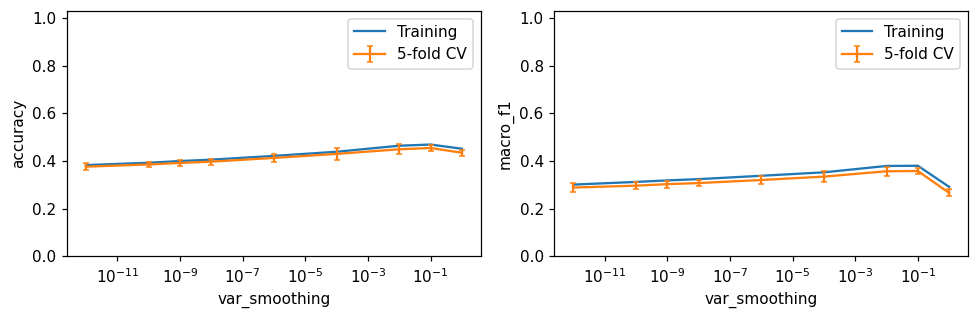

,smoothing,genre,precision,recall,f1,n,predicted
0,1.000000e-09,ambient,0.393701,0.649351,0.490196,77,127
1,1.000000e-09,black-metal,0.500000,0.100000,0.166667,10,2
2,1.000000e-09,bluegrass,0.238095,0.151515,0.185185,33,21
3,1.000000e-09,blues,0.181818,0.027778,0.048193,72,11
4,1.000000e-09,classical,0.500000,0.270270,0.350877,37,20
5,1.000000e-09,comedy,0.873239,0.805195,0.837838,77,71
6,1.000000e-09,country,0.125000,0.136364,0.130435,22,24
7,1.000000e-09,death-metal,0.272727,0.187500,0.222222,16,11
8,1.000000e-09,grunge,0.187500,0.157895,0.171429,19,16
9,1.000000e-09,heavy-metal,0.280000,0.600000,0.381818,35,75


,genre,n,zero_fraction,near_zero_fraction,mean,sd,gaussian_outside_0_1
0,ambient,385,0.054545,0.155844,0.681755,0.358947,0.216406
1,black-metal,46,0.021739,0.217391,0.389739,0.375791,0.202035
2,bluegrass,164,0.146341,0.682927,0.127907,0.284847,0.327804
3,blues,359,0.284123,0.796657,0.053530,0.162689,0.371065
4,classical,185,0.102703,0.275676,0.527496,0.398879,0.211102
5,comedy,382,0.871728,0.997382,0.000392,0.007003,0.477704
6,country,113,0.584071,0.946903,0.012097,0.087063,0.444747
7,death-metal,80,0.075000,0.300000,0.328495,0.351864,0.203427
8,grunge,94,0.382979,0.861702,0.034874,0.133381,0.396868
9,heavy-metal,178,0.162921,0.668539,0.086172,0.214782,0.344143


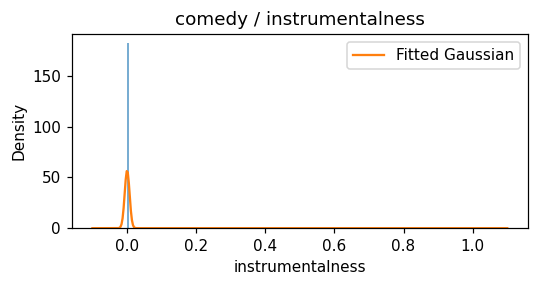

,genre,n,energy_loudness_corr
0,ambient,385,0.800867
1,black-metal,46,0.568378
2,bluegrass,164,0.731730
3,blues,359,0.744469
4,classical,185,0.800315
5,comedy,382,0.486094
6,country,113,0.696932
7,death-metal,80,0.643847
8,grunge,94,0.585509
9,heavy-metal,178,0.625374


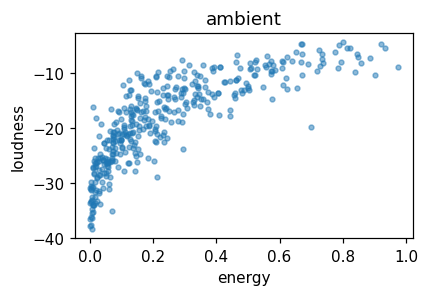

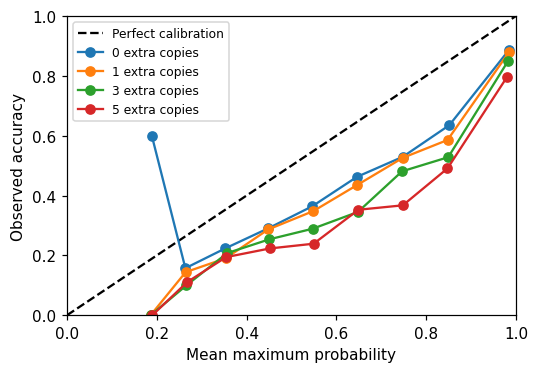

,copies,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,death-metal_recall_mean,...,salsa_precision_mean,salsa_precision_std,salsa_recall_mean,salsa_recall_std,rare_precision_mean,rare_precision_std,rare_recall_mean,rare_recall_std,confidence_mean,confidence_std
0,0,0.454717,0.014505,0.358046,0.011194,0.454717,0.014505,0.325754,0.175786,0.225,...,0.224300,0.054277,0.714286,0.172670,0.265248,0.042795,0.339921,0.046979,0.601923,0.007038
1,1,0.448585,0.019244,0.355317,0.017578,0.448585,0.019244,0.354752,0.184947,0.300,...,0.238738,0.055983,0.714286,0.172670,0.246801,0.038718,0.357074,0.054773,0.617828,0.007369
2,3,0.427123,0.018857,0.337288,0.023223,0.427123,0.018857,0.267399,0.127105,0.375,...,0.248800,0.047269,0.664286,0.149083,0.191054,0.045121,0.368795,0.066156,0.642346,0.006278
3,5,0.402594,0.015412,0.318701,0.018646,0.402594,0.015412,0.242238,0.086623,0.475,...,0.263569,0.049752,0.639286,0.110368,0.185364,0.037817,0.384015,0.055119,0.664016,0.008065


,copies,bin,n,confidence,accuracy
0,0,1,10,0.188816,0.600000
1,0,2,382,0.263605,0.157068
2,0,3,738,0.352849,0.223577
3,0,4,720,0.448149,0.290278
4,0,5,588,0.546160,0.363946
5,0,6,385,0.645776,0.462338
6,0,7,287,0.748220,0.529617
7,0,8,233,0.851678,0.635193
8,0,9,897,0.985006,0.887402
9,1,1,7,0.186190,0.000000


In [4]:
tr,va,sc,xt,xv=fold_data[0]
gnb_default=GaussianNB().fit(xt,y[tr])
q=0
probs=gnb_default.predict_proba(xv[[q]])[0]
order=np.argsort(probs)[::-1][:2]; A,B=order
x=xv[q]
terms=-.5*np.log(gnb_default.var_[A]/gnb_default.var_[B])-.5*(
    (x-gnb_default.theta_[A])**2/gnb_default.var_[A]-(x-gnb_default.theta_[B])**2/gnb_default.var_[B])
prior=np.log(gnb_default.class_prior_[A]/gnb_default.class_prior_[B])
logp=gnb_default.predict_log_proba(xv[[q]])[0]
assert np.isclose(prior+terms.sum(),logp[A]-logp[B])
term_table=pd.DataFrame({'term':['prior']+FEATURES,'contribution':np.r_[prior,terms],
    'x':[np.nan]+list(x),'mean_A':[np.nan]+list(gnb_default.theta_[A]),
    'var_A':[np.nan]+list(gnb_default.var_[A]),'mean_B':[np.nan]+list(gnb_default.theta_[B]),
    'var_B':[np.nan]+list(gnb_default.var_[B])})
save_table('gnb_terms',term_table)
summary['gnb_prediction']={'row':int(train_ids[va[q]]),'true':names[y[va[q]]],
    'A':names[A],'B':names[B],'p_A':float(probs[A]),'p_B':float(probs[B]),
    'log_ratio':float(prior+terms.sum())}
print(summary['gnb_prediction'])
print('Local sklearn source:')
print('\n'.join(line for line in inspect.getsource(GaussianNB._partial_fit).splitlines()
                if 'epsilon_' in line or 'np.var' in line))
scale_rows=[]; scale_details=[]
for scale in [False,True]:
    r,pred=evaluate(GaussianNB(),scale)
    scale_rows.append({'input':'standardized' if scale else 'raw',**r})
    for fold,(tr,va,sc,xt,xv) in enumerate(fold_data):
        m=GaussianNB().fit(xt if scale else X[tr],y[tr])
        scale_details.append({'input':'standardized' if scale else 'raw','fold':fold+1,
            'epsilon':m.epsilon_,'largest_variance_feature':FEATURES[np.argmax(np.var(xt if scale else X[tr],axis=0))],
            'max_variance':float(np.var(xt if scale else X[tr],axis=0).max())})
save_table('gnb_scale',pd.DataFrame(scale_rows))
save_table('gnb_epsilon',pd.DataFrame(scale_details))
smooth_rows=[]
for v in [1e-12,1e-10,1e-9,1e-8,1e-6,1e-4,1e-2,1e-1,1]:
    r,pred=evaluate(GaussianNB(var_smoothing=v),True)
    smooth_rows.append({'var_smoothing':v,**r})
smooth_table=save_table('gnb_smoothing',pd.DataFrame(smooth_rows))
best_smooth=float(smooth_table.loc[smooth_table.macro_f1_mean.idxmax(),'var_smoothing'])
summary['gnb_smoothing']=best_smooth
curves(smooth_table,'var_smoothing','gnb_smoothing',True)
# Find the most extreme standardized within-genre variance using training data only.
full_sc=StandardScaler().fit(X); Xs=full_sc.transform(X)
variance_rows=[]
for c in labels:
    for j,f in enumerate(FEATURES):
        variance_rows.append({'genre':names[c],'feature':f,'variance':float(np.var(Xs[y==c,j])),
            'unique':int(np.unique(X[y==c,j]).size),'n':int((y==c).sum())})
save_table('gnb_within_variances',pd.DataFrame(variance_rows).sort_values('variance'),False)
tr,va,sc,xt,xv=fold_data[0]
diagnostics=[]
for v in [1e-9,best_smooth]:
    m=GaussianNB(var_smoothing=v).fit(xt,y[tr]); pred=m.predict(xv)
    p,r,f,n=precision_recall_fscore_support(y[va],pred,labels=labels,zero_division=0)
    for c in labels:
        diagnostics.append({'smoothing':v,'genre':names[c],'precision':p[c],'recall':r[c],
            'f1':f[c],'n':n[c],'predicted':int((pred==c).sum())})
save_table('gnb_default_diagnosis',pd.DataFrame(diagnostics))
# Within-genre Gaussian violation: bounded, strongly zero-heavy instrumentalness.
j=FEATURES.index('instrumentalness')
gaussian_rows=[]
for c in labels:
    z=X[y==c,j]; mu=z.mean(); sd=z.std()
    gaussian_rows.append({'genre':names[c],'n':len(z),'zero_fraction':np.mean(z==0),
        'near_zero_fraction':np.mean(z<.01),'mean':mu,'sd':sd,
        'gaussian_outside_0_1':norm.cdf(0,mu,sd)+1-norm.cdf(1,mu,sd)})
gaussian_table=save_table('gnb_gaussian_violation',pd.DataFrame(gaussian_rows))
genre=gaussian_table.sort_values('zero_fraction',ascending=False).iloc[0].genre
z=X[y==encoder.transform([genre])[0],j]
fig,ax=plt.subplots(figsize=(5,2.7)); ax.hist(z,bins=25,density=True,alpha=.6)
grid=np.linspace(min(-.1,z.min()),max(1.1,z.max()),400)
ax.plot(grid,norm.pdf(grid,z.mean(),z.std()),label='Fitted Gaussian')
ax.set(title=genre+' / instrumentalness',xlabel='instrumentalness',ylabel='Density'); ax.legend()
savefig('gnb_non_gaussian')
cor_rows=[]
for c in labels:
    a=X[y==c,FEATURES.index('energy')]; b=X[y==c,FEATURES.index('loudness')]
    cor_rows.append({'genre':names[c],'n':len(a),'energy_loudness_corr':np.corrcoef(a,b)[0,1]})
cor_table=save_table('gnb_correlations',pd.DataFrame(cor_rows))
c=encoder.transform([cor_table.iloc[cor_table.energy_loudness_corr.abs().argmax()].genre])[0]
fig,ax=plt.subplots(figsize=(4,2.8))
ax.scatter(X[y==c,FEATURES.index('energy')],X[y==c,FEATURES.index('loudness')],s=10,alpha=.5)
ax.set(xlabel='energy',ylabel='loudness',title=names[c]); savefig('gnb_dependence')
confidence_rows=[]; calibration_rows=[]
fig,ax=plt.subplots(figsize=(5,3.5)); ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
for copies in [0,1,3,5]:
    pp=np.empty((len(y),20)); ss=[]
    for tr,va,sc,xt,xv in fold_data:
        j=FEATURES.index('energy')
        a=np.c_[xt,np.repeat(xt[:,[j]],copies,axis=1)]
        b=np.c_[xv,np.repeat(xv[:,[j]],copies,axis=1)]
        m=GaussianNB(var_smoothing=best_smooth).fit(a,y[tr])
        pp[va]=m.predict_proba(b)
        ss.append({**metrics(y[va],pp[va].argmax(axis=1)),
            'confidence':pp[va].max(axis=1).mean()})
    confidence_rows.append({'copies':copies,**pack(ss)})
    conf=pp.max(axis=1); correct=pp.argmax(axis=1)==y
    bin_id=np.minimum((conf*10).astype(int),9)
    points=[]
    for b in range(10):
        mask=bin_id==b
        if mask.any():
            row={'copies':copies,'bin':b,'n':int(mask.sum()),
                'confidence':float(conf[mask].mean()),'accuracy':float(correct[mask].mean())}
            calibration_rows.append(row); points.append(row)
    t=pd.DataFrame(points); ax.plot(t.confidence,t.accuracy,'o-',label=f'{copies} extra copies')
ax.set(xlabel='Mean maximum probability',ylabel='Observed accuracy',xlim=(0,1),ylim=(0,1))
ax.legend(fontsize=8); savefig('gnb_reliability')
save_table('gnb_confidence',pd.DataFrame(confidence_rows))
save_table('gnb_calibration_bins',pd.DataFrame(calibration_rows),False)

## 3.3 決策樹與 ensembles
使用 Gini、best split、無 class weighting。Bagging 每棵樹以 bootstrap 抽 n 筆、使用全部特徵；RF 每個 split 隨機抽 sqrt(13) 的特徵。樹預設不限制深度、min_samples_leaf=1。所有比較用相同五折。

,max_depth,depth_label,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,...,train_black-metal_recall_std,train_salsa_precision_mean,train_salsa_precision_std,train_salsa_recall_mean,train_salsa_recall_std,train_rare_precision_mean,train_rare_precision_std,train_rare_recall_mean,train_rare_recall_std,leaves_mean
0,1,1,0.202594,0.003673,0.055565,0.001574,0.202594,0.003673,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.0
1,2,2,0.270047,0.005896,0.084946,0.002937,0.270047,0.005896,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.0
2,3,3,0.330896,0.016182,0.138315,0.007049,0.330896,0.016182,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.0
3,5,5,0.383255,0.007364,0.207291,0.013348,0.383255,0.007364,0.150983,0.140631,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.033047,0.030576,0.048750,0.044667,19.6
4,8,8,0.434434,0.006906,0.300030,0.011190,0.434434,0.006906,0.373413,0.166208,...,0.115131,0.111111,0.248452,0.032258,0.072131,0.448338,0.087213,0.217456,0.010591,106.4
5,12,12,0.435377,0.010055,0.342055,0.012856,0.435377,0.010055,0.277906,0.127299,...,0.101562,0.651511,0.115756,0.404637,0.090219,0.806327,0.023946,0.629881,0.060982,502.8
6,20,20,0.419575,0.013352,0.323757,0.015419,0.419575,0.013352,0.252857,0.126778,...,0.012087,1.000000,0.000000,0.967742,0.032258,0.997545,0.003456,0.979780,0.015277,1165.6
7,100,None,0.412736,0.009248,0.312147,0.005938,0.412736,0.009248,0.246405,0.095862,...,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1194.8


,min_samples_leaf,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,death-metal_recall_mean,...,train_black-metal_recall_std,train_salsa_precision_mean,train_salsa_precision_std,train_salsa_recall_mean,train_salsa_recall_std,train_rare_precision_mean,train_rare_precision_std,train_rare_recall_mean,train_rare_recall_std,leaves_mean
0,1,0.412736,0.009248,0.312147,0.005938,0.412736,0.009248,0.246405,0.095862,0.2375,...,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1194.8
1,2,0.412500,0.011951,0.312906,0.014039,0.412500,0.011951,0.226861,0.078276,0.2250,...,0.023814,0.962771,0.051001,0.557258,0.133260,0.845011,0.014537,0.696380,0.024658,854.0
2,5,0.431604,0.015865,0.328541,0.016813,0.431604,0.015865,0.289697,0.094417,0.2500,...,0.091691,0.616667,0.074536,0.429839,0.129397,0.595334,0.028632,0.484829,0.068642,426.8
3,10,0.442689,0.005692,0.335709,0.003790,0.442689,0.005692,0.279304,0.169676,0.1875,...,0.084683,0.440899,0.121904,0.313306,0.103626,0.486855,0.013205,0.335147,0.045315,223.2
4,30,0.437972,0.013589,0.302578,0.016240,0.437972,0.013589,0.335357,0.101867,0.2875,...,0.207025,0.000000,0.000000,0.000000,0.000000,0.163980,0.066807,0.154227,0.044877,78.0
5,100,0.410613,0.015676,0.250100,0.021444,0.410613,0.015676,0.000000,0.000000,0.0000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.019635,0.026904,0.040000,0.054789,25.4
6,500,0.339858,0.018857,0.134069,0.007448,0.339858,0.018857,0.000000,0.000000,0.0000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.0


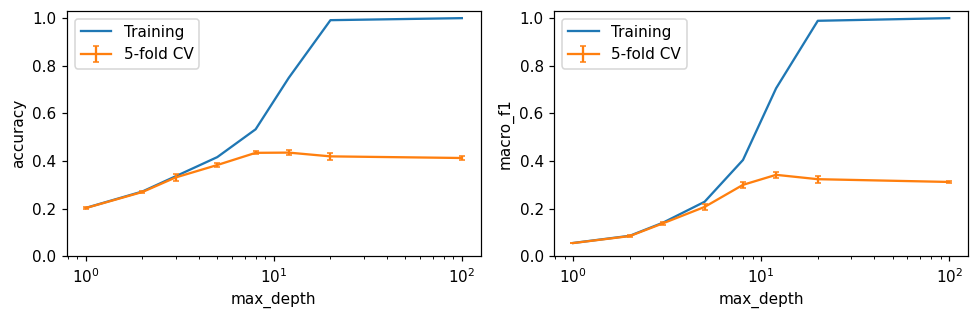

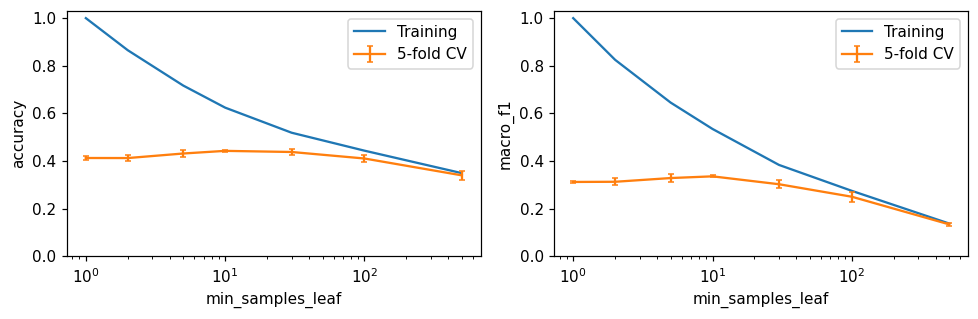

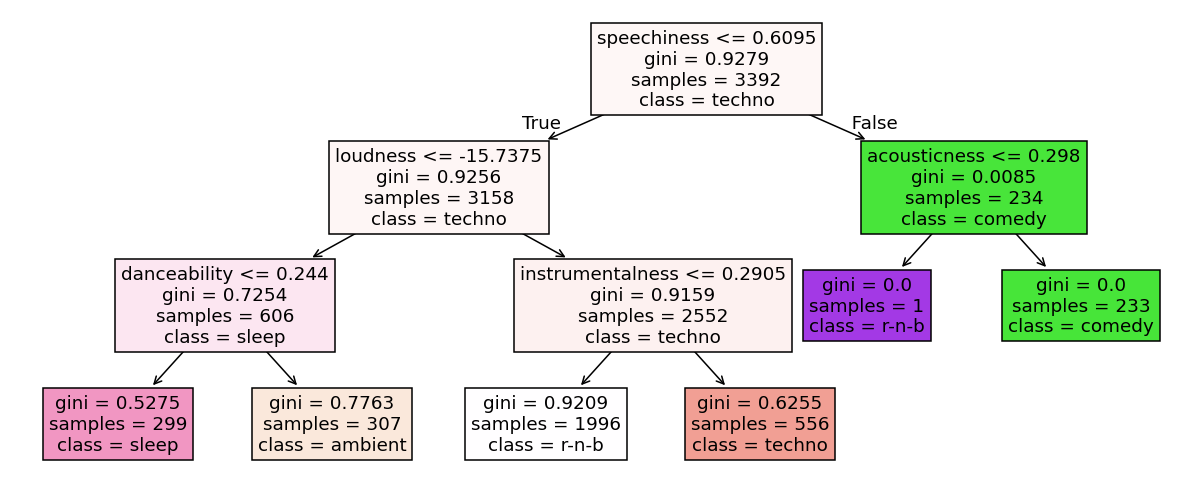

,node,depth,feature,threshold,n,gini,local_impurity_decrease,weighted_decrease,left_top,right_top
0,0,0,speechiness,0.6095,3392,0.927867,0.065493,0.065493,techno,comedy
1,1,1,loudness,-15.7375,3158,0.925643,0.046320,0.043125,sleep,techno
2,2,2,danceability,0.2440,606,0.725419,0.071890,0.012844,sleep,ambient
3,5,2,instrumentalness,0.2905,2552,0.915869,0.059330,0.044638,r-n-b,techno
4,8,1,acousticness,0.2980,234,0.008510,0.008510,0.000587,r-n-b,comedy


{'never_predict_first_fold': ['black-metal', 'bluegrass', 'blues', 'classical', 'country', 'death-metal', 'grunge', 'heavy-metal', 'hip-hop', 'jazz', 'opera', 'punk', 'reggae', 'salsa', 'tango'], 'never_predict_oof': ['black-metal', 'bluegrass', 'classical', 'country', 'death-metal', 'grunge', 'heavy-metal', 'hip-hop', 'jazz', 'opera', 'punk', 'reggae', 'salsa', 'tango']}


,family,n_estimators,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,...,train_black-metal_recall_mean,train_black-metal_recall_std,train_salsa_precision_mean,train_salsa_precision_std,train_salsa_recall_mean,train_salsa_recall_std,train_rare_precision_mean,train_rare_precision_std,train_rare_recall_mean,train_rare_recall_std
0,bagging,1,0.398585,0.016446,0.304176,0.024052,0.398585,0.016446,0.284950,0.146311,...,0.695946,0.085199,0.776190,0.081891,0.608468,0.116591,0.710307,0.033837,0.681109,0.064849
1,bagging,10,0.485142,0.015966,0.383174,0.019164,0.485142,0.015966,0.221270,0.126235,...,0.967568,0.029607,1.000000,0.000000,0.961694,0.041759,0.993146,0.004718,0.977204,0.011208
2,bagging,50,0.513679,0.015116,0.410267,0.027986,0.513679,0.015116,0.272253,0.109960,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
3,bagging,100,0.525236,0.012961,0.415398,0.012570,0.525236,0.012961,0.279569,0.084669,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
4,bagging,300,0.527358,0.013116,0.423056,0.020653,0.527358,0.013116,0.293687,0.125082,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
5,random_forest,1,0.370519,0.010124,0.271171,0.009857,0.370519,0.010124,0.182706,0.083054,...,0.685135,0.095507,0.664839,0.091553,0.634073,0.129649,0.674981,0.038747,0.668116,0.047754
6,random_forest,10,0.472877,0.013025,0.361421,0.016743,0.472877,0.013025,0.309667,0.130045,...,0.978228,0.022660,1.000000,0.000000,0.974395,0.026932,0.996793,0.004016,0.983078,0.007079
7,random_forest,50,0.535142,0.015294,0.426311,0.012368,0.535142,0.015294,0.350793,0.073832,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
8,random_forest,100,0.541981,0.008887,0.426662,0.021215,0.541981,0.008887,0.400467,0.073761,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
9,random_forest,300,0.546462,0.008446,0.432170,0.020374,0.546462,0.008446,0.389798,0.082052,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000


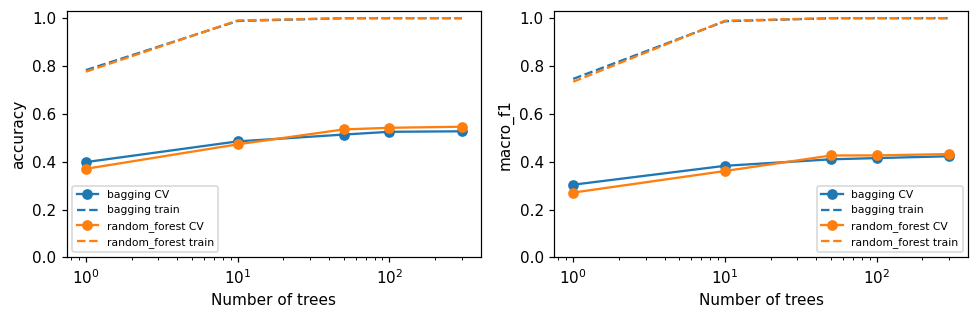

,fold,family,disagreement,accuracy_rep1,accuracy_rep2
0,1,single_tree,0.623821,0.403302,0.382075
1,1,bagging,0.312500,0.508255,0.484670
2,1,random_forest,0.238208,0.515330,0.510613
3,2,single_tree,0.653302,0.359670,0.423349
4,2,bagging,0.323113,0.509434,0.531840
5,2,random_forest,0.227594,0.535377,0.547170
6,3,single_tree,0.594340,0.410377,0.398585
7,3,bagging,0.306604,0.511792,0.511792
8,3,random_forest,0.244104,0.531840,0.536557
9,4,single_tree,0.648585,0.383255,0.375000


,family,mean,std
0,bagging,0.317689,0.020672
1,random_forest,0.242925,0.010481
2,single_tree,0.623113,0.028063


In [5]:
depths=[1,2,3,5,8,12,20,None]
leaves_grid=[1,2,5,10,30,100,500]
depth_rows=[]; leaf_rows=[]
for depth in depths:
    r,pred=evaluate(DecisionTreeClassifier(max_depth=depth,random_state=SEED))
    depth_rows.append({'max_depth':100 if depth is None else depth,'depth_label':'None' if depth is None else str(depth),**r})
for leaf in leaves_grid:
    r,pred=evaluate(DecisionTreeClassifier(min_samples_leaf=leaf,random_state=SEED))
    leaf_rows.append({'min_samples_leaf':leaf,**r})
depth_table=save_table('tree_depth',pd.DataFrame(depth_rows))
leaf_table=save_table('tree_leaf',pd.DataFrame(leaf_rows))
curves(depth_table,'max_depth','tree_depth',True)
curves(leaf_table,'min_samples_leaf','tree_leaf',True)
tr,va,sc,xt,xv=fold_data[0]
small=DecisionTreeClassifier(max_depth=3,random_state=SEED).fit(X[tr],y[tr])
fig,ax=plt.subplots(figsize=(11,4.6))
artists=plot_tree(small,feature_names=FEATURES,class_names=list(names),filled=True,rounded=False,
    fontsize=12,impurity=True,proportion=False,precision=4,ax=ax)
# The 20-class count vectors obscure the splits; keep split, Gini, sample size and majority class.
import re
for artist in artists:
    artist.set_text(re.sub(r'\nvalue = \[.*?\]', '', artist.get_text(), flags=re.S))
savefig('tree_depth3')
tree=small.tree_; split_rows=[]
def walk(node,depth):
    left,right=tree.children_left[node],tree.children_right[node]
    if left<0: return
    n=tree.n_node_samples[node]; nl=tree.n_node_samples[left]; nr=tree.n_node_samples[right]
    gain=tree.impurity[node]-nl/n*tree.impurity[left]-nr/n*tree.impurity[right]
    split_rows.append({'node':node,'depth':depth,'feature':FEATURES[tree.feature[node]],
        'threshold':tree.threshold[node],'n':n,'gini':tree.impurity[node],
        'local_impurity_decrease':gain,'weighted_decrease':gain*n/tree.n_node_samples[0],
        'left_top':names[tree.value[left][0].argmax()],
        'right_top':names[tree.value[right][0].argmax()]})
    walk(left,depth+1); walk(right,depth+1)
walk(0,0)
save_table('tree_splits',pd.DataFrame(split_rows))
leaf_nodes=np.flatnonzero(tree.children_left<0)
predicted_classes=set(tree.value[leaf_nodes,0,:].argmax(axis=1))
small_oof=evaluate(DecisionTreeClassifier(max_depth=3,random_state=SEED))[1]
summary['small_tree']={'never_predict_first_fold':[names[c] for c in labels if c not in predicted_classes],
    'never_predict_oof':[names[c] for c in labels if c not in set(small_oof)]}
print(summary['small_tree'])

tree_candidates=[(DecisionTreeClassifier(max_depth=d,random_state=SEED),depth_rows[i]) for i,d in enumerate(depths)]
tree_candidates += [(DecisionTreeClassifier(min_samples_leaf=l,random_state=SEED),leaf_rows[i]) for i,l in enumerate(leaves_grid)]
best_tree,best_tree_row=max(tree_candidates,key=lambda pair:pair[1]['macro_f1_mean'])
tree_counts=[1,10,50,100,300]
ensemble_rows=[]
for family in ['bagging','random_forest']:
    scores={n:[] for n in tree_counts}; train_scores={n:[] for n in tree_counts}
    for tr,va in folds:
        if family=='bagging':
            m=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED),
                n_estimators=1,max_samples=1.,max_features=1.,bootstrap=True,
                random_state=SEED,n_jobs=1,warm_start=True)
        else:
            m=RandomForestClassifier(n_estimators=1,max_features='sqrt',bootstrap=True,
                random_state=SEED,n_jobs=1,warm_start=True)
        for n in tree_counts:
            m.set_params(n_estimators=n).fit(X[tr],y[tr])
            scores[n].append(metrics(y[va],m.predict(X[va])))
            train_scores[n].append(metrics(y[tr],m.predict(X[tr])))
    for n in tree_counts:
        r={'family':family,'n_estimators':n,**pack(scores[n])}
        r.update({'train_'+k:v for k,v in pack(train_scores[n]).items()})
        ensemble_rows.append(r)
ensemble_table=save_table('ensemble_size',pd.DataFrame(ensemble_rows))
fig,axs=plt.subplots(1,2,figsize=(9,3))
for family in ['bagging','random_forest']:
    t=ensemble_table[ensemble_table.family==family]
    for ax,metric in zip(axs,['accuracy','macro_f1']):
        line,=ax.plot(t.n_estimators,t[metric+'_mean'],'o-',label=family+' CV')
        ax.plot(t.n_estimators,t['train_'+metric+'_mean'],'--',color=line.get_color(),label=family+' train')
        ax.set(xlabel='Number of trees',ylabel=metric,xscale='log',ylim=(0,1.03)); ax.legend(fontsize=7)
savefig('ensemble_size')
best_ensembles={}
for family in ['bagging','random_forest']:
    t=ensemble_table[ensemble_table.family==family]
    best_ensembles[family]=int(t.loc[t.macro_f1_mean.idxmax(),'n_estimators'])
# Train twice on paired bootstrap samples of EACH fold's training part, compare on its untouched validation part.
stability_rows=[]
for fold,(tr,va) in enumerate(folds):
    rng=np.random.default_rng(SEED+fold)
    samples=[rng.choice(tr,size=len(tr),replace=True) for _ in range(2)]
    for family in ['single_tree','bagging','random_forest']:
        preds=[]
        for rep,idx in enumerate(samples):
            if family=='single_tree': m=DecisionTreeClassifier(random_state=SEED)
            elif family=='bagging': m=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED),
                n_estimators=300,random_state=SEED,n_jobs=1)
            else: m=RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=1,max_features='sqrt')
            m.fit(X[idx],y[idx]); preds.append(m.predict(X[va]))
        stability_rows.append({'fold':fold+1,'family':family,
            'disagreement':float(np.mean(preds[0]!=preds[1])),
            'accuracy_rep1':accuracy_score(y[va],preds[0]),'accuracy_rep2':accuracy_score(y[va],preds[1])})
stability_table=save_table('ensemble_stability',pd.DataFrame(stability_rows))
save_table('ensemble_stability_summary',stability_table.groupby('family').disagreement.agg(['mean','std']).reset_index())
summary['best_ensembles']=best_ensembles

## 3.4 RBF SVM
StandardScaler 每折各自 fit。C=0.1 到 1000、gamma=0.001 到 10，各跨四個數量級。tol=0.001、max_iter=-1（不預先截斷），不加 class weighting。調參時 probability=False；只有最終模型若選到 SVM 才開啟概率估計，random_state 固定。

Finished SVM C = 0.1


Finished SVM C = 1


Finished SVM C = 10


Finished SVM C = 100


Finished SVM C = 1000


,C,gamma,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,death-metal_precision_mean,death-metal_precision_std,...,train_black-metal_recall_mean,train_black-metal_recall_std,train_salsa_precision_mean,train_salsa_precision_std,train_salsa_recall_mean,train_salsa_recall_std,train_rare_precision_mean,train_rare_precision_std,train_rare_recall_mean,train_rare_recall_std
0,0.1,0.001,0.227123,0.004975,0.070631,0.002423,0.227123,0.004975,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.1,0.010,0.376415,0.017519,0.157257,0.007534,0.376415,0.017519,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.1,0.100,0.439858,0.008666,0.230402,0.003931,0.439858,0.008666,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.1,1.000,0.133726,0.000646,0.011798,0.000048,0.133726,0.000646,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.1,10.000,0.133726,0.000646,0.011795,0.000050,0.133726,0.000646,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,1.0,0.001,0.378538,0.016425,0.162699,0.007338,0.378538,0.016425,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,1.0,0.010,0.475708,0.004975,0.288748,0.008059,0.475708,0.004975,0.483333,0.314024,...,0.027177,0.019114,0.000000,0.000000,0.000000,0.000000,0.274392,0.091703,0.028560,0.007696
7,1.0,0.100,0.504481,0.008059,0.351602,0.014525,0.504481,0.008059,0.425758,0.127264,...,0.195796,0.052677,0.837121,0.109128,0.218347,0.059002,0.772611,0.097133,0.242961,0.015514
8,1.0,1.000,0.398821,0.004119,0.259391,0.012105,0.398821,0.004119,0.600000,0.547723,...,0.880480,0.014308,1.000000,0.000000,0.820565,0.048597,0.998571,0.001957,0.834629,0.012299
9,1.0,10.000,0.134670,0.000987,0.013006,0.000700,0.134670,0.000987,0.000000,0.000000,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000


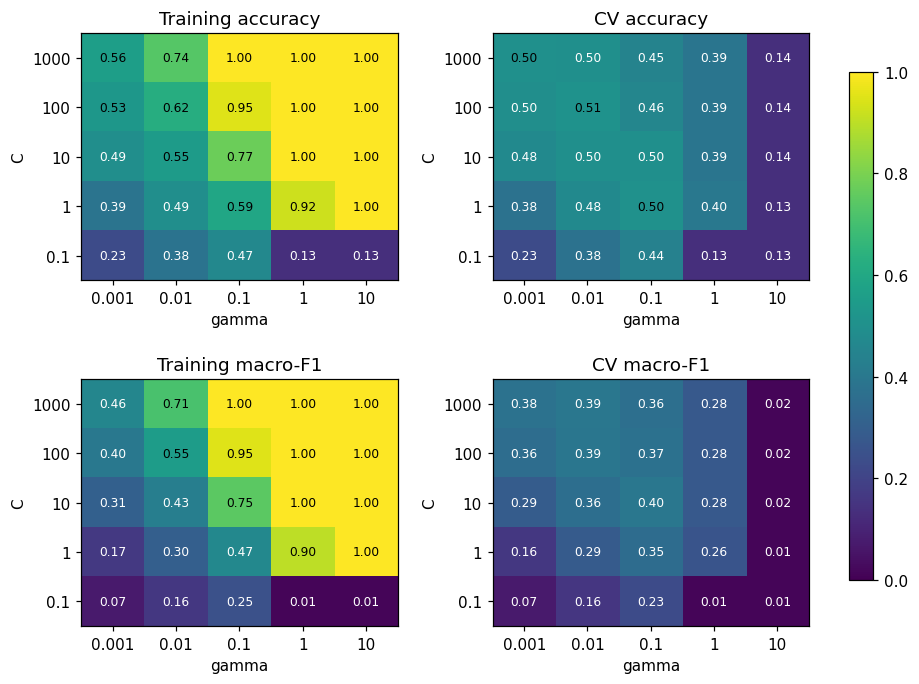

,C,gamma,genre,n_train,support_count,support_fraction,cv_f1,cv_f1_std
0,0.1,0.01,ambient,385,383,0.994805,0.501256,0.060149
1,0.1,0.01,black-metal,46,46,1.000000,0.000000,0.000000
2,0.1,0.01,bluegrass,164,164,1.000000,0.000000,0.000000
3,0.1,0.01,blues,359,359,1.000000,0.251164,0.014177
4,0.1,0.01,classical,185,185,1.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...
95,1000.0,0.01,reggae,128,116,0.906250,0.321177,0.138226
96,1000.0,0.01,salsa,39,34,0.871795,0.470800,0.074399
97,1000.0,0.01,sleep,329,170,0.516717,0.765446,0.044261
98,1000.0,0.01,tango,66,62,0.939394,0.422780,0.197775


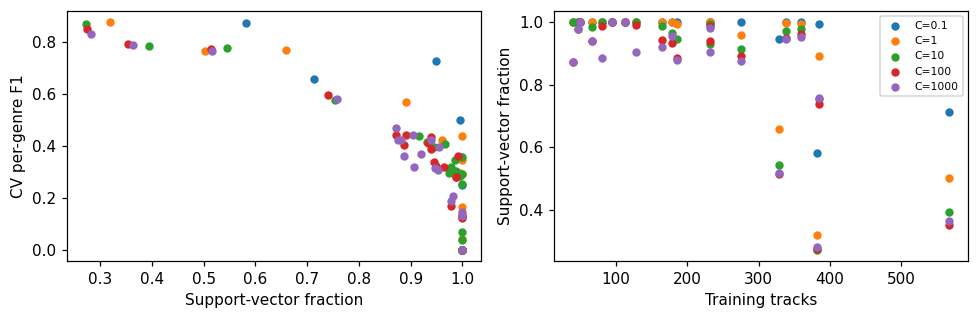

In [6]:
Cs=[.1,1,10,100,1000]
gammas=[.001,.01,.1,1,10]
svm_rows=[]
for C in Cs:
    for gamma in gammas:
        r,pred=evaluate(SVC(C=C,gamma=gamma,kernel='rbf',cache_size=512,
            random_state=SEED),True)
        svm_rows.append({'C':C,'gamma':gamma,**r})
    print('Finished SVM C =',C,flush=True)
svm_table=save_table('svm_grid',pd.DataFrame(svm_rows))
best_svm_row=svm_table.loc[svm_table.macro_f1_mean.idxmax()]
best_C=float(best_svm_row.C); best_gamma=float(best_svm_row.gamma)
summary['svm']={'C':best_C,'gamma':best_gamma}
fig,axs=plt.subplots(2,2,figsize=(9,7))
for ax,key,title in zip(axs.flat,['train_accuracy_mean','accuracy_mean','train_macro_f1_mean','macro_f1_mean'],
    ['Training accuracy','CV accuracy','Training macro-F1','CV macro-F1']):
    z=svm_table.pivot(index='C',columns='gamma',values=key).reindex(index=Cs,columns=gammas)
    im=ax.imshow(z,origin='lower',vmin=0,vmax=1,aspect='auto')
    ax.set(xticks=range(5),xticklabels=gammas,yticks=range(5),yticklabels=Cs,xlabel='gamma',ylabel='C',title=title)
    for i in range(5):
        for j in range(5): ax.text(j,i,f'{z.iloc[i,j]:.2f}',ha='center',va='center',color='white' if z.iloc[i,j]<.5 else 'black',fontsize=8)
fig.subplots_adjust(wspace=.3,hspace=.4,right=.86)
colorbar_ax=fig.add_axes([.90,.17,.025,.66])
fig.colorbar(im,cax=colorbar_ax)
fig.savefig(OUT/'svm_grid.png',dpi=180,bbox_inches='tight'); plt.show(); plt.close()
sv_rows=[]
for C in [.1,1,10,100,1000]:
    model=SVC(C=C,gamma=.01,kernel='rbf',random_state=SEED,cache_size=512).fit(Xs,y)
    r,pred=evaluate(SVC(C=C,gamma=.01,random_state=SEED,cache_size=512),True)
    p,rec,f,n=precision_recall_fscore_support(y,pred,labels=labels,zero_division=0)
    # F1 mean across folds, rather than F1 of pooled OOF predictions.
    ff=[]
    for tr,va in folds:
        ff.append(precision_recall_fscore_support(y[va],pred[va],labels=labels,zero_division=0)[2])
    for c in labels:
        sv_rows.append({'C':C,'gamma':.01,'genre':names[c],'n_train':int((y==c).sum()),
            'support_count':int(model.n_support_[c]),'support_fraction':model.n_support_[c]/(y==c).sum(),
            'cv_f1':float(np.mean(ff,axis=0)[c]),'cv_f1_std':float(np.std(ff,axis=0,ddof=1)[c])})
sv_table=save_table('svm_support_vectors',pd.DataFrame(sv_rows))
fig,axs=plt.subplots(1,2,figsize=(9,3))
for C in [.1,1,10,100,1000]:
    t=sv_table[sv_table.C==C]
    axs[0].scatter(t.support_fraction,t.cv_f1,s=20,label=f'C={C:g}')
    axs[1].scatter(t.n_train,t.support_fraction,s=20,label=f'C={C:g}')
axs[0].set(xlabel='Support-vector fraction',ylabel='CV per-genre F1')
axs[1].set(xlabel='Training tracks',ylabel='Support-vector fraction'); axs[1].legend(fontsize=7)
savefig('svm_support_vectors')

## 4.1 多類別比較
每家族選 CV macro-F1 最高的設定；樹家族包含單樹、bagging、RF。以下先鎖定全部多類別與二類別設定及門檻，再執行最後的 test cell。

In [7]:
bag_n=best_ensembles['bagging']; rf_n=best_ensembles['random_forest']
bag=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED),n_estimators=bag_n,random_state=SEED,n_jobs=1)
rf=RandomForestClassifier(n_estimators=rf_n,max_features='sqrt',random_state=SEED,n_jobs=1)
models={'kNN':(KNeighborsClassifier(n_neighbors=best_k,algorithm='brute',n_jobs=1),True),
    'GaussianNB':(GaussianNB(var_smoothing=best_smooth),True),
    'DecisionTree':(best_tree,False),'Bagging':(bag,False),'RandomForest':(rf,False),
    'SVM':(SVC(C=best_C,gamma=best_gamma,cache_size=512,random_state=SEED),True)}
comparison=[]
for name,(m,scale) in models.items():
    if name=='kNN': r=knn_table.set_index('k').loc[best_k].to_dict()
    elif name=='GaussianNB': r=smooth_table.set_index('var_smoothing').loc[best_smooth].to_dict()
    elif name=='SVM': r=best_svm_row.drop(['C','gamma']).to_dict()
    elif name=='DecisionTree': r={k:v for k,v in best_tree_row.items() if k.endswith('_mean') or k.endswith('_std')}
    else:
        family='bagging' if name=='Bagging' else 'random_forest'
        r=ensemble_table[(ensemble_table.family==family)&(ensemble_table.n_estimators==(bag_n if name=='Bagging' else rf_n))].iloc[0].drop(['family','n_estimators']).to_dict()
    comparison.append({'model':name,**r})
comparison_table=save_table('multiclass_cv',pd.DataFrame(comparison))
best_name=comparison_table.loc[comparison_table.macro_f1_mean.idxmax(),'model']
tree_family=comparison_table[comparison_table.model.isin(['DecisionTree','Bagging','RandomForest'])]
summary['tree_family_winner']=tree_family.loc[tree_family.macro_f1_mean.idxmax(),'model']
summary['multiclass_winner']=best_name
summary['model_parameters']={name:str(m.get_params()) for name,(m,_) in models.items()}
print('Multiclass model locked:',best_name)

,model,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,train_micro_f1_mean,train_micro_f1_std,train_death-metal_precision_mean,train_death-metal_precision_std,train_death-metal_recall_mean,...,black-metal_recall_std,salsa_precision_mean,salsa_precision_std,salsa_recall_mean,salsa_recall_std,rare_precision_mean,rare_precision_std,rare_recall_mean,rare_recall_std,leaves_mean
0,kNN,0.569340,0.002565,0.491692,0.008133,0.569340,0.002565,0.513212,0.046033,0.387500,...,0.124127,0.596667,0.275479,0.364286,0.131587,0.317758,0.074007,0.196491,0.035978,NaN
1,GaussianNB,0.469340,0.001956,0.380081,0.002723,0.469340,0.001956,0.366524,0.047504,0.253125,...,0.078724,0.224300,0.054277,0.714286,0.172670,0.265248,0.042795,0.339921,0.046979,NaN
2,DecisionTree,0.749233,0.010357,0.705390,0.016923,0.749233,0.010357,0.835241,0.057542,0.803125,...,0.129004,0.355000,0.271800,0.225000,0.162980,0.256596,0.046063,0.199928,0.025870,502.8
3,Bagging,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,0.103518,0.620000,0.246757,0.328571,0.136347,0.373039,0.041374,0.242301,0.056472,NaN
4,RandomForest,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,0.094803,0.650000,0.418330,0.225000,0.205396,0.451579,0.051210,0.218467,0.064256,NaN
5,SVM,0.773998,0.006373,0.748896,0.010529,0.773998,0.006373,0.837899,0.029042,0.806250,...,0.125117,0.505000,0.094478,0.464286,0.152048,0.322682,0.049639,0.287496,0.072996,NaN


Multiclass model locked: RandomForest


## 4.2 hip-hop 二類別模型與門檻
重新訓練 binary labels，不把多類別預測直接當 detector。比較 RF、SVM 兩家族；以 CV average precision 選參數，因為正例少且關心被挑出來的歌曲。沿用相同五折（對 20 類分層也維持 binary 比例）。RF 使用概率，SVM 使用 decision score。

選最高 CV AP 的 detector，再從其 training OOF scores 找 recall >=0.8 中最高的門檻，減少要聽的歌曲。不看 test 分數選門檻。

In [8]:
yb=(y==encoder.transform(['hip-hop'])[0]).astype(int)
binary_candidates=[]
for C in [.1,1,10]:
    for gamma in [.001,.01,.1]:
        binary_candidates.append(('SVM',{'C':C,'gamma':gamma},
            SVC(C=C,gamma=gamma,random_state=SEED,cache_size=512),True))
for depth in [5,12,None]:
    binary_candidates.append(('RandomForest',{'max_depth':depth},
        RandomForestClassifier(n_estimators=300,max_depth=depth,random_state=SEED,n_jobs=1),False))
binary_rows=[]; binary_cache={}
for idx,(name,params,model,scale) in enumerate(binary_candidates):
    scores=np.empty(len(y)); fold_scores=[]
    for tr,va,sc,xt,xv in fold_data:
        a,b=(xt,xv) if scale else (X[tr],X[va])
        m=clone(model).fit(a,yb[tr])
        scores[va]=m.decision_function(b) if name=='SVM' else m.predict_proba(b)[:,1]
        fold_scores.append({'AP':average_precision_score(yb[va],scores[va]),
                            'ROC_AUC':roc_auc_score(yb[va],scores[va])})
    binary_rows.append({'candidate':idx,'family':name,'parameters':str(params),**pack(fold_scores)})
    binary_cache[idx]=scores
binary_table=save_table('binary_cv',pd.DataFrame(binary_rows))
binary_best={}
for name in ['SVM','RandomForest']:
    t=binary_table[binary_table.family==name]
    binary_best[name]=int(t.loc[t.AP_mean.idxmax(),'candidate'])
detector_id=int(binary_table.loc[binary_table.AP_mean.idxmax(),'candidate'])
detector_name=binary_candidates[detector_id][0]
oof_scores=binary_cache[detector_id]
precision,recall,thresholds=precision_recall_curve(yb,oof_scores)
eligible=np.flatnonzero(recall[:-1]>=.8)
threshold=float(thresholds[eligible[-1]])
oof_pred=(oof_scores>=threshold).astype(int)
assert recall_score(yb,oof_pred)>=.8
summary['binary']={'best_by_family':binary_best,'threshold_family':detector_name,
    'threshold_candidate':detector_id,'threshold':threshold,
    'oof_recall':recall_score(yb,oof_pred),'oof_flagged':int(oof_pred.sum())}
save_table('binary_oof_threshold',pd.DataFrame({'row':train_ids,'is_hiphop':yb,
    'score':oof_scores,'flagged':oof_pred}),False)
print('Threshold locked:',summary['binary'])
(OUT/'selection_before_test.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')

,candidate,family,parameters,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std
0,0,SVM,"{'C': 0.1, 'gamma': 0.001}",0.106681,0.018819,0.730590,0.038749
1,1,SVM,"{'C': 0.1, 'gamma': 0.01}",0.279768,0.046755,0.861083,0.015824
2,2,SVM,"{'C': 0.1, 'gamma': 0.1}",0.321631,0.045855,0.855766,0.025372
3,3,SVM,"{'C': 1, 'gamma': 0.001}",0.166773,0.037301,0.793442,0.032406
4,4,SVM,"{'C': 1, 'gamma': 0.01}",0.320721,0.043264,0.882344,0.019676
5,5,SVM,"{'C': 1, 'gamma': 0.1}",0.318974,0.042635,0.855582,0.025266
6,6,SVM,"{'C': 10, 'gamma': 0.001}",0.292921,0.038978,0.863931,0.014369
7,7,SVM,"{'C': 10, 'gamma': 0.01}",0.317041,0.041417,0.881425,0.018509
8,8,SVM,"{'C': 10, 'gamma': 0.1}",0.322983,0.031681,0.869111,0.020237
9,9,RandomForest,{'max_depth': 5},0.407105,0.091485,0.900525,0.017115


Threshold locked: {'best_by_family': {'SVM': 8, 'RandomForest': 10}, 'threshold_family': 'RandomForest', 'threshold_candidate': 10, 'threshold': 0.07541857749161833, 'oof_recall': 0.8008658008658008, 'oof_flagged': 872}


3875

## 最終 test 評估
所有選擇已固定；此處才讀 test 的特徵與標籤。test 結果不回頭改參數或門檻。SVM 若當選，類別預測仍用 predict，OvR AUC 用各類概率（兩者可能不完全一致，屬 SVC 的概率估計特性）。

,ambient,black-metal,bluegrass,blues,classical,comedy,country,death-metal,grunge,heavy-metal,...,jazz,opera,punk,r-n-b,reggae,salsa,sleep,tango,techno,true_genre
0,73,0,1,2,0,1,0,0,0,2,...,3,1,2,2,0,0,4,1,4,ambient
1,0,1,0,0,0,0,0,4,0,6,...,0,0,0,0,0,0,0,0,1,black-metal
2,4,0,12,6,2,0,0,0,0,0,...,7,0,1,7,0,1,0,0,1,bluegrass
3,5,0,5,33,0,1,2,0,1,3,...,7,0,8,16,0,0,0,0,6,blues
4,16,0,0,2,16,0,0,0,0,0,...,4,0,0,2,0,0,5,0,1,classical
5,0,0,0,3,0,75,0,0,0,0,...,0,0,3,6,0,0,0,0,1,comedy
6,0,0,1,4,0,0,4,0,0,0,...,2,0,6,6,0,1,0,0,1,country
7,0,0,0,0,0,0,0,8,0,9,...,0,0,0,0,0,0,0,0,3,death-metal
8,2,0,0,4,0,0,3,1,1,4,...,0,0,7,0,0,0,0,0,2,grunge
9,2,0,0,4,0,0,0,3,1,21,...,0,0,9,0,0,0,0,0,4,heavy-metal


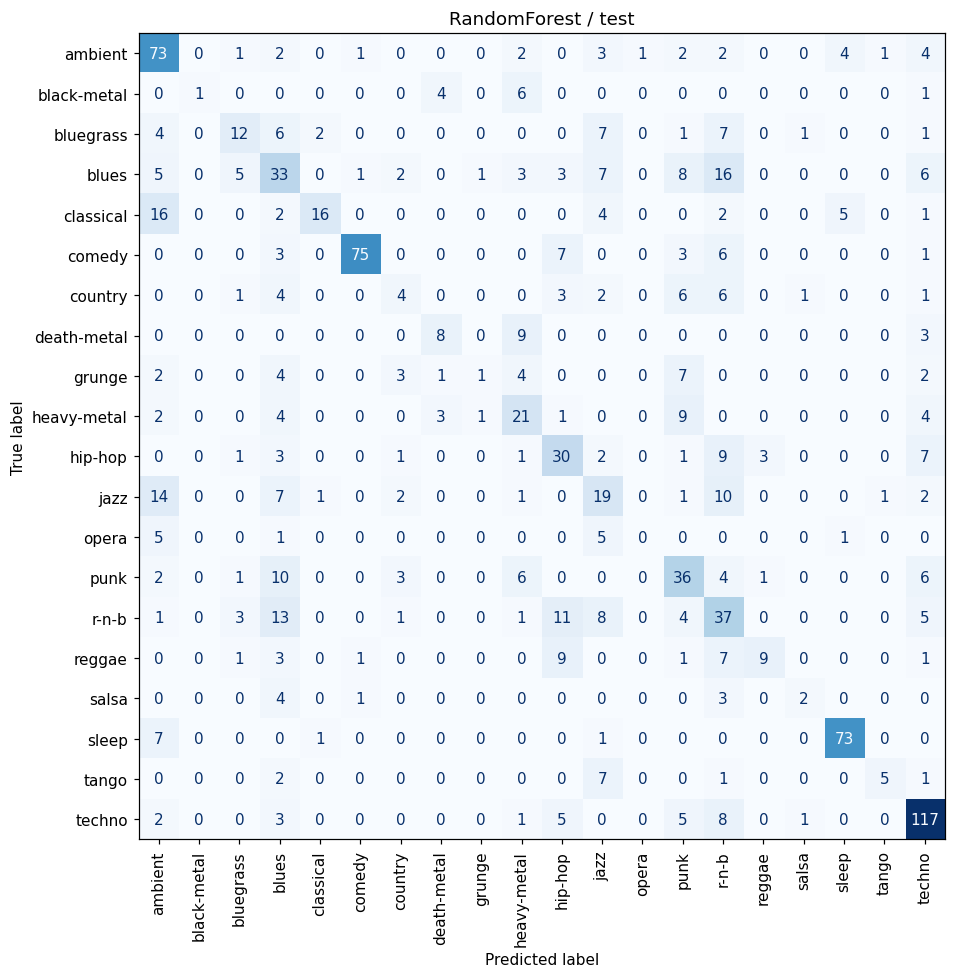

,genre,n_test,precision,recall,f1,ovr_auc,most_confused_with,confused_count
0,ambient,96,0.548872,0.760417,0.637555,0.936819,sleep,4
1,black-metal,12,1.000000,0.083333,0.153846,0.987039,heavy-metal,6
2,bluegrass,41,0.480000,0.292683,0.363636,0.932478,jazz,7
3,blues,90,0.317308,0.366667,0.340206,0.832852,r-n-b,16
4,classical,46,0.800000,0.347826,0.484848,0.943476,ambient,16
5,comedy,95,0.949367,0.789474,0.862069,0.984178,hip-hop,7
6,country,28,0.250000,0.142857,0.181818,0.850464,punk,6
7,death-metal,20,0.500000,0.400000,0.444444,0.985313,heavy-metal,9
8,grunge,24,0.333333,0.041667,0.074074,0.905808,punk,7
9,heavy-metal,45,0.381818,0.466667,0.420000,0.947772,punk,9


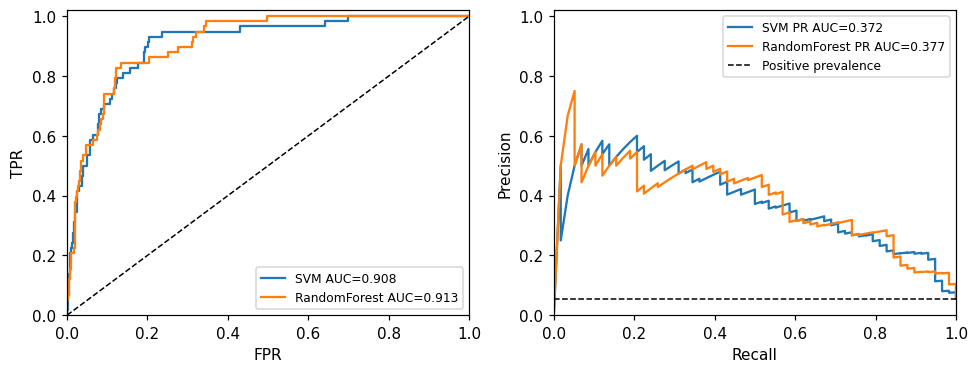

,family,threshold,TN,FP,FN,TP,accuracy,TPR,TNR,PPV,NPV,F1,ROC_AUC,PR_AUC_trapezoid,AP
0,SVM,0.0,990,12,44,14,0.94717,0.241379,0.988024,0.538462,0.957447,0.333333,0.907926,0.371983,0.384458
1,RandomForest,0.5,994,8,51,7,0.94434,0.120690,0.992016,0.466667,0.951196,0.191781,0.912726,0.376802,0.389297


,TN,FP,FN,TP,accuracy,TPR,TNR,PPV,NPV,F1,family,threshold,listen_per_1000,missed_hiphop_per_1000,test_recall_at_least_80_percent
0,839,163,9,49,0.837736,0.844828,0.837325,0.231132,0.989387,0.362963,RandomForest,0.075419,200.0,8.490566,True


Multiclass test: {'accuracy': 0.539622641509434, 'macro_f1': np.float64(0.4167158608569982), 'micro_f1': 0.539622641509434, 'death-metal_precision': np.float64(0.5), 'death-metal_recall': np.float64(0.4), 'tango_precision': np.float64(0.7142857142857143), 'tango_recall': np.float64(0.3125), 'opera_precision': np.float64(0.0), 'opera_recall': np.float64(0.0), 'black-metal_precision': np.float64(1.0), 'black-metal_recall': np.float64(0.08333333333333333), 'salsa_precision': np.float64(0.4), 'salsa_recall': np.float64(0.2), 'rare_precision': np.float64(0.5228571428571429), 'rare_recall': np.float64(0.19916666666666666)}
Never-positive baseline: {'TN': 1002, 'FP': 0, 'FN': 58, 'TP': 0, 'accuracy': 0.9452830188679245, 'TPR': 0.0, 'TNR': 1.0, 'PPV': 0.0, 'NPV': 0.9452830188679245, 'F1': 0.0}
Complete. Results saved in HW2_results_113062273


In [9]:
Xtest=X_all[test_ids]; ytest=y_all[test_ids]
model,scale=models[best_name]
model=clone(model)
if best_name=='SVM': model.set_params(probability=True)
final_model=make_pipeline(StandardScaler(),model) if scale else model
final_model.fit(X,y)
yp=final_model.predict(Xtest); proba=final_model.predict_proba(Xtest)
assert np.isfinite(proba).all() and np.allclose(proba.sum(axis=1),1)
summary['multiclass_test']=metrics(ytest,yp)
cm=confusion_matrix(ytest,yp,labels=labels)
save_table('multiclass_confusion',pd.DataFrame(cm,columns=names).assign(true_genre=names))
fig,ax=plt.subplots(figsize=(10,9))
ConfusionMatrixDisplay(cm,display_labels=names).plot(ax=ax,cmap='Blues',colorbar=False,xticks_rotation=90,values_format='d')
ax.set_title(best_name+' / test'); savefig('multiclass_confusion')
p,r,f,n=precision_recall_fscore_support(ytest,yp,labels=labels,zero_division=0)
genre_rows=[]
for c in labels:
    wrong=cm[c].copy(); wrong[c]=0; other=int(wrong.argmax())
    genre_rows.append({'genre':names[c],'n_test':int(n[c]),'precision':p[c],'recall':r[c],'f1':f[c],
        'ovr_auc':roc_auc_score((ytest==c).astype(int),proba[:,c]),
        'most_confused_with':names[other] if wrong[other] else '', 'confused_count':int(wrong[other])})
save_table('multiclass_test_by_genre',pd.DataFrame(genre_rows))
save_table('multiclass_test_predictions',pd.DataFrame({'row':test_ids,'true':names[ytest],
    'predicted':names[yp],**{f'p_{name}':proba[:,c] for c,name in enumerate(names)}}),False)
ybtest=(ytest==encoder.transform(['hip-hop'])[0]).astype(int)
def binary_metrics(yt,pred):
    tn,fp,fn,tp=confusion_matrix(yt,pred,labels=[0,1]).ravel()
    def div(a,b): return float(a/b) if b else 0.
    return {'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),'accuracy':div(tp+tn,len(yt)),
        'TPR':div(tp,tp+fn),'TNR':div(tn,tn+fp),'PPV':div(tp,tp+fp),
        'NPV':div(tn,tn+fn),'F1':div(2*tp,2*tp+fp+fn)}
binary_test_rows=[]; test_scores={}
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
for name,idx in binary_best.items():
    _,params,m,scale=binary_candidates[idx]
    final=make_pipeline(StandardScaler(),clone(m)) if scale else clone(m)
    final.fit(X,yb)
    score=final.decision_function(Xtest) if name=='SVM' else final.predict_proba(Xtest)[:,1]
    default=0. if name=='SVM' else .5
    pred=(score>=default).astype(int); test_scores[name]=score
    fpr,tpr,_=roc_curve(ybtest,score)
    prec,rec,_=precision_recall_curve(ybtest,score)
    pr_auc=auc(rec,prec); roc_auc=roc_auc_score(ybtest,score)
    binary_test_rows.append({'family':name,'threshold':default,**binary_metrics(ybtest,pred),
        'ROC_AUC':roc_auc,'PR_AUC_trapezoid':pr_auc,'AP':average_precision_score(ybtest,score)})
    axs[0].plot(fpr,tpr,label=f'{name} AUC={roc_auc:.3f}')
    axs[1].plot(rec,prec,label=f'{name} PR AUC={pr_auc:.3f}')
axs[0].plot([0,1],[0,1],'k--',linewidth=1)
axs[1].axhline(ybtest.mean(),color='k',linestyle='--',linewidth=1,label='Positive prevalence')
axs[0].set(xlabel='FPR',ylabel='TPR'); axs[1].set(xlabel='Recall',ylabel='Precision')
for ax in axs: ax.legend(fontsize=8); ax.set_xlim(0,1); ax.set_ylim(0,1.02)
savefig('binary_roc_pr')
save_table('binary_test_default',pd.DataFrame(binary_test_rows))
summary['binary_never_positive']=binary_metrics(ybtest,np.zeros(len(ybtest),dtype=int))
cost=binary_metrics(ybtest,(test_scores[detector_name]>=threshold).astype(int))
cost.update({'family':detector_name,'threshold':threshold,
    'listen_per_1000':(cost['TP']+cost['FP'])/len(ybtest)*1000,
    'missed_hiphop_per_1000':cost['FN']/len(ybtest)*1000,
    'test_recall_at_least_80_percent':bool(cost['TPR']>=.8)})
summary['binary_curator']=cost
save_table('binary_curator',pd.DataFrame([cost]))
save_table('binary_test_scores',pd.DataFrame({'row':test_ids,'is_hiphop':ybtest,**test_scores}),False)
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('Multiclass test:',summary['multiclass_test'])
print('Never-positive baseline:',summary['binary_never_positive'])
print('Complete. Results saved in',OUT)

## 檢查
所有 test 預測由前面固定的設定產生。不要因 test 分數不好而更換模型或調整門檻。
數值為五折平均 ± 樣本標準差；test per-genre 指標只使用一次保留測試集。Rare genres 的 precision、recall 在各參數表中逐項與平均列出。

In [10]:
assert np.isclose(f1_score(ytest,yp,average='micro'),accuracy_score(ytest,yp))
assert cm.sum()==1060 and sum(summary['binary_never_positive'][k] for k in ['TN','FP','FN','TP'])==1060
assert len(pd.read_csv(OUT/'knn_noise_per_track.csv'))==4*4240
assert len(pd.read_csv(OUT/'gnb_terms.csv'))==14
assert (knn_table.loc[knn_table.k==1,'train_accuracy_mean']==1).all()
assert len(pd.read_csv(OUT/'svm_support_vectors.csv'))==5*20
print('Checks passed: split, OOF coverage, k=1, 14 NB terms, probabilities, confusion matrices, micro-F1.')

Checks passed: split, OOF coverage, k=1, 14 NB terms, probabilities, confusion matrices, micro-F1.
